# Extended Recurrence Plot Analysis of Spatial Data - Tutorial

This Jupyter notebook provides an introduction to the repository. In this notebook, we will create and analyze a recurrence plot of two-dimensional data. Therefore, we will first create an image, the distance matrix, and the recurrence plot, and then analyze the structures within the recurrence plot in more detail. Then, the measures of the Recurrence Quantification Analysis (RQA) will be extracted from the recurrence plot. For the theoretical background, please consider the thesis at `latex/thesis.pdf`.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda
import os

gpu_available = cuda.is_available()
print("GPU available:", gpu_available)

GPU available: True


## Import code from the repository

`grqa` contains all code regarding the RQA, while `utils` contains useful helper functions. The import will issue a warning if no GPU is available on your device. The functions for GPU are significantly faster, but there are CPU versions of all functions available. For this notebook it is not necessary to have a GPU since the data is not very large.  

In [2]:
from scripts import grqa
from scripts import utils

## Create a Test Image

Here, the image is created that will be analyzed later in this notebook. Feel free to replace this image with any other (grayscale) 
image of your liking. You can also explore `utils/test_images.py` for more options.

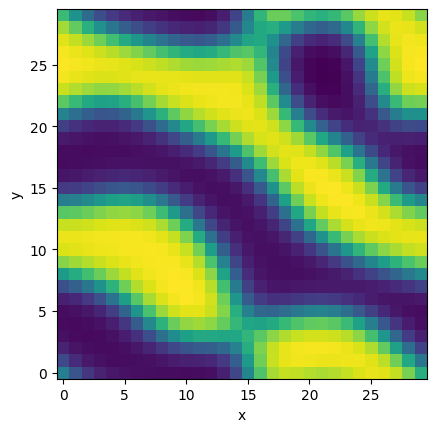

In [3]:
img = utils.get_turing_test_image(30)

plt.imshow(img, origin="lower")
plt.xlabel("x")
plt.ylabel("y")
plt.show()
plt.close()

## Distance Matrix and Recurrence Plot

Since the above image is rather small, it is possible to compute the distance matrix and the recurrence plot since it fits into the device memory. Since the distance matrix and recurrence plot will have a size of $(\text{x-extent} \cdot \text{y-extent})^2$ it gets very large for larger images and might not fit into memory. 

In [4]:
dm = grqa.distance_matrix(img) # distance matrix
RR = 0.2 # recurrence rate
epsilon = grqa.recurrence_threshold(dm, RR) # recurrence threshold
rp = grqa.recurrence_plot(dm, epsilon) # recurrence plot

Since the distance matrix and the recurrence plot are four-dimensional, only a subset can be visualized. We could for example visualize a plane where one image column is compared to itself $(x_1 = x_2 = \text{fixed})$.

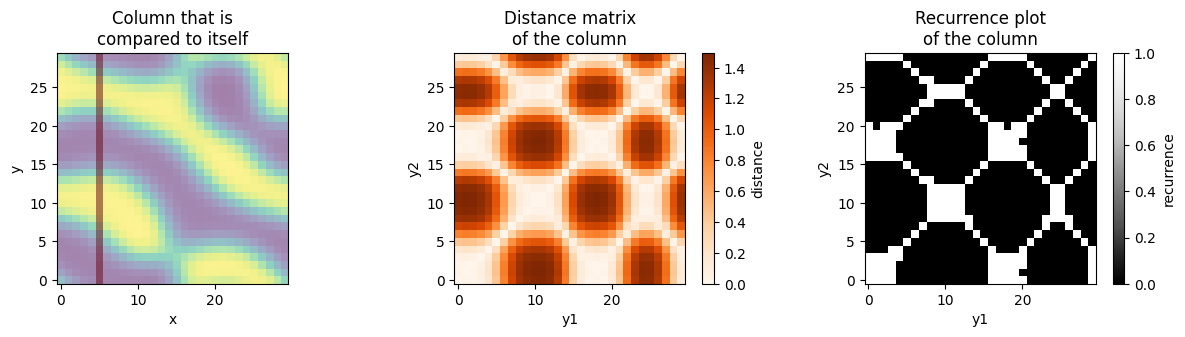

In [5]:
# set x1 = x2
x1 = 5
x2 = x1

# extract plane from the recurrence plot
plane1_rp = rp[:, x1, :, x2]
plane1_dm = dm[:, x1, :, x2] / np.sqrt(2) # distance matrix contains pairwise eulidean distances

# column overlay for image
overlay = np.ones_like(img) * np.nan
overlay[:, x1] = 1

# plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3))

ax1.imshow(img, origin="lower", alpha=0.5)
ax1.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Column that is\ncompared to itself")

cb = ax2.imshow(plane1_dm, origin="lower", cmap="Oranges")
ax2.set_xlabel("y1")
ax2.set_ylabel("y2")
ax2.set_title("Distance matrix\nof the column")
plt.colorbar(cb, label="distance")

cb = ax3.imshow(plane1_rp, origin="lower", cmap="Greys_r")
ax3.set_xlabel("y1")
ax3.set_ylabel("y2")
ax3.set_title("Recurrence plot\nof the column")
plt.colorbar(cb, label="recurrence")

plt.show()
plt.close()

Alternatively, we could plot a plane where each column is compared to one pixel within the respective column $(y_2 = \text{fixed}, x_1 = x_2)$.

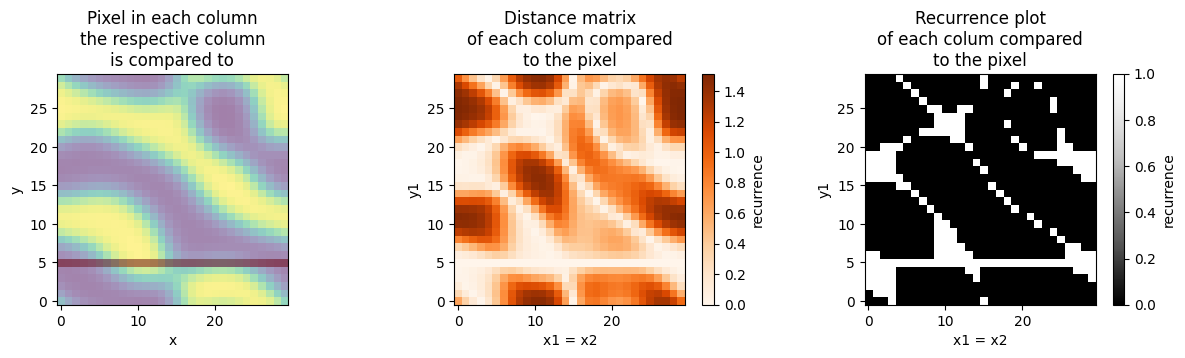

In [6]:
# set y2
y2 = 5

# extract plane from the recurrence plot
plane2_rp = np.zeros((rp.shape[0], rp.shape[1]))
plane2_dm = np.zeros((dm.shape[0], dm.shape[1]))

for x in range(rp.shape[1]):
    for y in range(rp.shape[0]):
        col_rp = rp[:, x, y2, x]
        plane2_rp[:, x] = col_rp
        col_dm = dm[:, x, y2, x] / np.sqrt(2) # distance matrix contains pairwise eulidean distances
        plane2_dm[:, x] = col_dm

# column overlay for image
overlay = np.ones_like(img) * np.nan
overlay[y2, :] = 1

# plot
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 3))

ax1.imshow(img, origin="lower", alpha=0.5)
ax1.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Pixel in each column\nthe respective column\nis compared to")

cb = ax2.imshow(plane2_dm, origin="lower", cmap="Oranges")
ax2.set_xlabel("x1 = x2")
ax2.set_ylabel("y1")
ax2.set_title("Distance matrix\nof each colum compared\nto the pixel")
plt.colorbar(cb, label="recurrence")

cb = ax3.imshow(plane2_rp, origin="lower", cmap="Greys_r")
ax3.set_xlabel("x1 = x2")
ax3.set_ylabel("y1")
ax3.set_title("Recurrence plot\nof each colum compared\nto the pixel")
plt.colorbar(cb, label="recurrence")

plt.show()
plt.close()

To get a nice visualization (including a 3d visualization) you can use one of the two functions from the repository:

In [7]:
# set output path
path = "img/tutorial"

if not os.path.exists(path):
    os.makedirs(path)

utils.plot_rp_3d_from_rp(rp, plot_path=path, name="from_rp") # from precalculated recurrence plot
utils.plot_rp_3d(img, plot_path=path, name="from_img", epsilon=epsilon) # directly from the image

## Lines and Patches in the Recurrence Plot

In the 4d recurrence plot, complex clusters of recurrences form. To quantify these clusters within a recurrence plot, one can count the number and size of either square patches that are formed by the recurrences (sample the clusters by square patches $\rightarrow$ patch sampling) or the number and length of lines (sample the clusters by lines $\rightarrow$ line sampling). Both the patches and the lines can appear in "diagonal" directions in the 4d recurrence plot or in "vertical/horizontal" directions (for an overview on all directions, see `latex/thesis.pdf`).  

The diagonal patches/lines in the recurrence plot indicate that a pattern within the image appears multiple times. Below, we will find examples of such patterns that create diagonal patches or lines. (This is very slow and should only be used for small images.)

In [8]:
# decode directions

arrow_map = {
    (1, 0): "↑", 
    (-1, 0): "↓",
    (0, 1): "→",
    (0, -1): "←",
    (1, 1): "↗",
    (1, -1): "↖",
    (-1, 1): "↘",
    (-1, -1): "↙",
    (0, 0): "•"
}

def decode_direction(direction_tuple):
    arrow = arrow_map.get(direction_tuple)
    return arrow

### Diagonal Patches

In [9]:
# get the diagonal square patches within the recurrence plot
rp_sum, diag_ind, diag_lengths, diag_dirs, _ = grqa.diag_hs_patch_sampling(
    rp, minlen=2, verbose=True, rot=True, return_distribution=False
)

Detecting diagonal HS in 16 direction(s)...


100%|█████████████████████████████████████████████| 4/4 [00:21<00:00,  5.31s/it]

236276 diagonal hypersurfaces of lenghts:
[ 2  3  4  5  6  7  8  9 10 30]
were detected.


Visualizing patch nr. 31211
Pattern directions: ↗ ↙


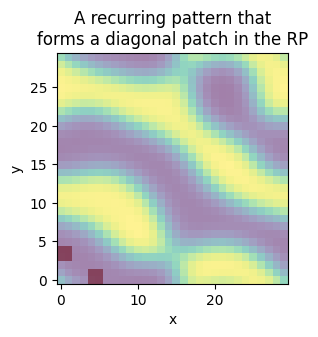

In [10]:
# choose a random patch
ind = np.random.choice(range(len(diag_lengths)))
print("Visualizing patch nr.", ind)
print("Pattern directions:", decode_direction(tuple(diag_dirs[ind, :2])), decode_direction(tuple(diag_dirs[ind, 2:])))

# create overlay 
overlay = np.ones_like(img) * np.nan

for length1 in range(diag_lengths[ind]):
    for length2 in range(diag_lengths[ind]):
        overlay[
            diag_ind[ind, 0] + diag_dirs[ind, 0] * length1,
            diag_ind[ind, 1] + diag_dirs[ind, 1] * length2,
        ] = 1
        overlay[
            diag_ind[ind, 2] + diag_dirs[ind, 2] * length1,
            diag_ind[ind, 3] + diag_dirs[ind, 3] * length2,
        ] = 1

# plot
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.imshow(img, origin="lower", alpha=0.5)
ax.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("A recurring pattern that\nforms a diagonal patch in the RP")

plt.show()
plt.close()

### Diagonal Lines

In [11]:
# get the diagonal diagonals within the recurrence plot
rp_sum, diag_ind, diag_lengths, diag_dirs, _ = grqa.diag_hs_line_sampling(
    rp, minlen=2, verbose=True, rot=True, return_distribution=False
)

Detecting diagonal lines in 64 directions...


100%|█████████████████████████████████████████████| 8/8 [01:10<00:00,  8.80s/it]


2291694 diagonal lines of lenghts:
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30]
were detected.


Visualizing line nr. 1021165
Pattern directions: ↘ ↓


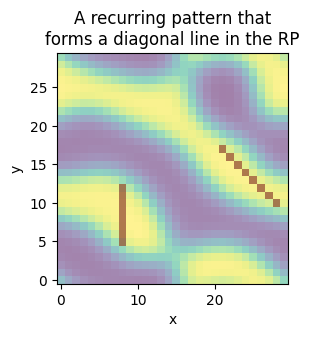

In [12]:
# choose a random line
ind = np.random.choice(range(len(diag_lengths)))
print("Visualizing line nr.", ind)
print("Pattern directions:", decode_direction(tuple(diag_dirs[ind, :2])), decode_direction(tuple(diag_dirs[ind, 2:])))

# create overlay 
overlay = np.ones_like(img) * np.nan

for length in range(diag_lengths[ind]):
    # first pattern
    overlay[
        diag_ind[ind, 0] + diag_dirs[ind, 0] * length,
        diag_ind[ind, 1] + diag_dirs[ind, 1] * length,
    ] = 1
    # second pattern
    overlay[
        diag_ind[ind, 2] + diag_dirs[ind, 2] * length,
        diag_ind[ind, 3] + diag_dirs[ind, 3] * length,
    ] = 1

# plot
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.imshow(img, origin="lower", alpha=0.5)
ax.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("A recurring pattern that\nforms a diagonal line in the RP")

plt.show()
plt.close()

Vertical patches/lines in the recurrence plot appear when a pixel value persists for a certain amount of pixels. The following plots show examples of individual pixels whose pixel value persists at other areas of the image. 

### Vertical Patches

In [13]:
# get the diagonal square patches within the recurrence plot
rp_sum, vert_ind, vert_lengths, vert_dirs, _ = grqa.vert_hs_patch_sampling(
    rp, 2, verbose=True, rot=True, return_distribution=False
)

Detecting vertical HS in 4 direction(s)...


100%|█████████████████████████████████████████████| 4/4 [00:04<00:00,  1.19s/it]

61223 vertical hypersurfaces of lenghts:
[2 3 4 5]
were detected.


Visualizing patch nr. 29867
Pattern directions: • ↘


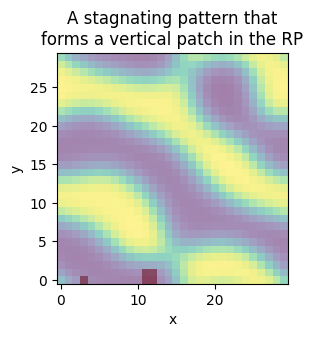

In [14]:
# choose a random patch
ind = np.random.choice(range(len(vert_lengths)))
print("Visualizing patch nr.", ind)
print("Pattern directions:", decode_direction((0, 0)), decode_direction(tuple(vert_dirs[ind])))

# create overlay 
overlay = np.ones_like(img) * np.nan

for length1 in range(vert_lengths[ind]):
    for length2 in range(vert_lengths[ind]):
        overlay[
            vert_ind[ind, 0],
            vert_ind[ind, 1],
        ] = 1
        overlay[
            vert_ind[ind, 2] + vert_dirs[ind, 0] * length1,
            vert_ind[ind, 3] + vert_dirs[ind, 1] * length2,
        ] = 1

# plot
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.imshow(img, origin="lower", alpha=0.5)
ax.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("A stagnating pattern that\nforms a vertical patch in the RP")

plt.show()
plt.close()

### Vertical Lines

In [15]:
# get the diagonal square patches within the recurrence plot
rp_sum, vert_ind, vert_lengths, vert_dirs, _ = grqa.vert_hs_line_sampling(
    rp, 2, verbose=True, rot=True, return_distribution=False
)

Detecting vertical lines in 8 directions...


100%|█████████████████████████████████████████████| 8/8 [00:07<00:00,  1.01it/s]

269574 vertical lines of lenghts:
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
were detected.


Visualizing line nr. 217591
Pattern directions: • ←


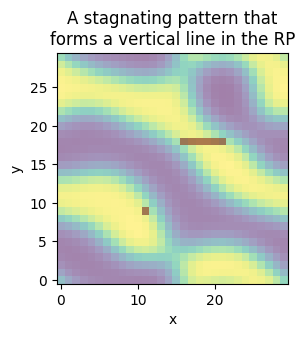

In [16]:
# choose a random line
ind = np.random.choice(range(len(vert_lengths)))
print("Visualizing line nr.", ind)
print("Pattern directions:", decode_direction((0, 0)), decode_direction(tuple(vert_dirs[ind])))

# create overlay 
overlay = np.ones_like(img) * np.nan

for length in range(vert_lengths[ind]):
    overlay[
        vert_ind[ind, 0],
        vert_ind[ind, 1],
    ] = 1
    overlay[
        vert_ind[ind, 2] + vert_dirs[ind, 0] * length,
        vert_ind[ind, 3] + vert_dirs[ind, 1] * length,
    ] = 1

# plot
fig, ax = plt.subplots(1, 1, figsize=(4, 3))

ax.imshow(img, origin="lower", alpha=0.5)
ax.imshow(overlay, origin="lower", cmap="Reds_r", alpha=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("A stagnating pattern that\nforms a vertical line in the RP")

plt.show()
plt.close()

## Recurrence Quatification Analysis

As explained earlier, the clusters of recurrences in the recurrence plot can be sampled by square patches or lines. The patch sampling approach is not suitable for parallelization, which is why the rest of this notebook focuses on the line sampling approach. Detecting lines within the recurrence plot is one way to quantify the structure. From the amount and distribution of the lengths of the diagonal and vertical/horizontal lines, different measures (**determinism (DET), average diagonal line length (L), entropy (ENT), laminarity (LAM), and trapping size (TS)**) can be computed that express different characteristics of the underlying data. For explanations and interpretations of the different measures, please go to `latex/thesis.pdf`.  

Next to the distribution of line lengths, the distribution of masses is an interesting characteristic of the recurrence plot. To get the distribution of masses, a grid with a box size $w$ is put over the recurrence plot. The sum of each box is the mass of the box. The mass distribution is the distribution of these individual masses. To get the **lacunarity (LAC)** measure, the sum of all masses for each box size is needed, as well as the sum of the squared masses. Further, the sum of masses and the sum of squared masses of the *inverse* recurrence plot needs to be computed. For more details, see `latex/thesis.pdf`.

The functions applied below are also suitable for larger images since they are faster, and the recurrence plot does not have to be pre-computed. There are CPU and GPU versions of each function. They are chosen depending on whether a GPU is available on your device.

<span style="color:gray">**Note:** you can also use the slow functions from above to get the line length/patch size distributions by setting ``return_distribution=True`` or use ``grqa.hs_patch_sampling_fast``.</span>

<span style="color:gray">**Note:** if you use the patch sampling approach, you need to use different equations for the DET and the LAM: ``grqa.determinism_and_avg_diag_hs_size_patch`` and ``laminarity_and_trapping_size_patch``</span>

### Estimation of the Recurrence Threshold ($\epsilon$)

For the example image in this notebook, we found $\epsilon$ already by using a percentile (the desired recurrence rate $RR=20\%$) of the distance matrix. For larger images, this might not work since we can't compute the whole distance matrix due to memory limitations. Instead, use ``utils.estimate_epsilon(img, RR, mode)`` which offers 3 different ways to estimate $\epsilon$:

* ``mode="whole"``: estimate $\epsilon$ from the whole image (like we did before)
* ``mode="corner"``: estimate $\epsilon$ from the upper left 50 x 50 px corner
* ``mode="random"``: estimate $\epsilon$ from a random 50 x 50 px block within the image.  

In the thesis, I estimated $\epsilon$ from 10 random 50 x 50 px blocks within the large images (repetition possible) and used the mean of all $\epsilon$s. In the end, you want to make sure you reach the desired $RR$ to compare the recurrence plots of different images to each other. This is why the line length/patch size functions below also return the $RR$.

### Get the Line Length Distribution

In [17]:
if gpu_available:
    (rp_sum, 
     lengths, 
     diag_frequ, 
     vert_frequ, 
     diag_dir_fac, 
     vert_dir_fac, 
     rr) = grqa.hs_line_sampling_gpu(img, epsilon=epsilon, rot=True, nthreads=(16, 16))
else:
    (rp_sum, 
     lengths, 
     diag_frequ, 
     vert_frequ, 
     diag_dir_fac, 
     vert_dir_fac, 
     rr) = grqa.hs_line_sampling_fast(img, epsilon=epsilon, rot=True) 

Epsilon: 0.1951448396254464
Copying data to GPU...
Copying data back to host... (run time: 0.00852346420288086)
copy back time: 0.00017547607421875, total time: 0.025421857833862305
2346128 diagonal lines of lenghts:
2 ... 30
were detected.
261960 vertical lines of lenghts:
2 ... 17
were detected.
The recurrence plot sum is: [162000].
The recurrence rate is: [0.2]


<span style="color:gray">**Note:** The amount of lines will differ a little from the results above, because in the first approach the lines are detected in the whole recurrence plot (meaning also lines that cross the main diagonal hyper surface), while in this second approach only the "upper triangle" of the recurrence plot is evaluated and the amount is then doubled (meaning no lines that cross the main diagonal hyper surface). Which approach suits best depends on the intention. In the thesis I used the second approach.</span>

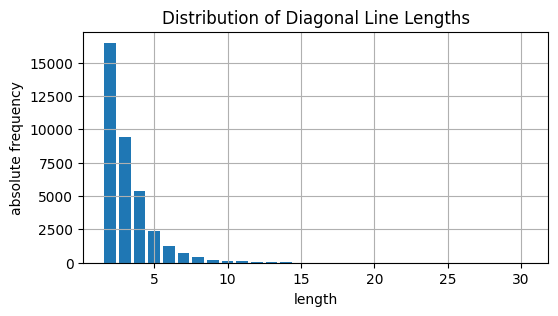

In [18]:
# visualize distribution of diagonal lines

fig, ax = plt.subplots(1, 1, figsize=(6, 3))

ax.bar(lengths, diag_frequ / diag_dir_fac)
ax.set_xlabel("length")
ax.set_ylabel("absolute frequency")
ax.set_title("Distribution of Diagonal Line Lengths")
ax.grid()

plt.show()
plt.close()

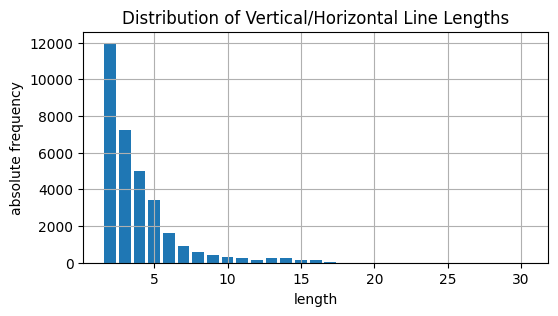

In [19]:
# visualize distribution of vertical/horizontal lines

fig, ax = plt.subplots(1, 1, figsize=(6, 3))

ax.bar(lengths, vert_frequ / vert_dir_fac)
ax.set_xlabel("length")
ax.set_ylabel("absolute frequency")
ax.set_title("Distribution of Vertical/Horizontal Line Lengths")
ax.grid()

plt.show()
plt.close()

### Get the Sum of Masses

In [20]:
max_box_size = 15 # maximum box size until which the mass distribution is computed

if gpu_available:
    (mass_distribution,
     mass_distribution_reverse, 
     mass_distribution_z2,
     mass_distribution_reverse_z2,
     nr_boxes) = grqa.mass_distribution_gpu(img, epsilon=epsilon, max_box_size=15, nthreads=(16, 16))
else:
    (mass_distribution,
     mass_distribution_reverse, 
     mass_distribution_z2,
     mass_distribution_reverse_z2,
     nr_boxes) = grqa.mass_distribution_fast(img, epsilon=epsilon, max_box_size=max_box_size)

Epsilon: 0.1951448396254464
Copying data to GPU...
Calculating the mass of all boxes up to size 15... (copy time: 0.0014772415161132812)
Copying data back to host... (run time: 0.07752442359924316)
copy back time: 0.00020313262939453125, total time: 0.07920718193054199


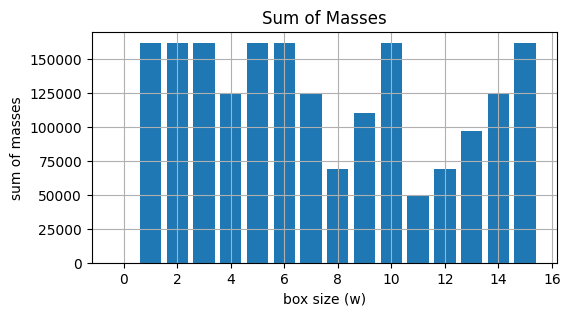

In [21]:
# visualize the sum of masses

fig, ax = plt.subplots(1, 1, figsize=(6, 3))

ax.bar(np.arange(max_box_size+1), mass_distribution)
ax.set_xlabel("box size (w)")
ax.set_ylabel("sum of masses")
ax.set_title("Sum of Masses")
ax.grid()

plt.show()
plt.close()

For larger images consider ``grqa.mass_distribution_gpu_rand`` or ``grqa.mass_distribution_gpu_large`` to either use a random subset of boxes to compute the sum of masses from or to compute the sum of masses for larger box sizes using intermediate results from smaller box sizes.

### Measures based on the Distribution of Diagonal Line Lengths (DET, L, ENT)

In [22]:
det, l = grqa.determinism_and_avg_diag_hs_size(diag_frequ, lengths, rp_sum, dir_fac=diag_dir_fac)
ent = grqa.entropy(diag_frequ)

print("DET:", det)
print("L:", l)
print("ENT:", ent)

DET: 0.7225486111111111
L: 3.1930840943034653
ENT: 1.5085981629827832


### Measures based on the Distribution of Vertical Line Lengths (LAM, TS)

In [23]:
lam, ts = grqa.laminarity_and_trapping_size(vert_frequ, lengths, rp_sum, dir_fac=vert_dir_fac)

print("LAM:", lam)
print("TS:", ts)

LAM: 0.7846851851851852
TS: 3.8820888685295465


### Measures based on the Sum of Masses (LAC)

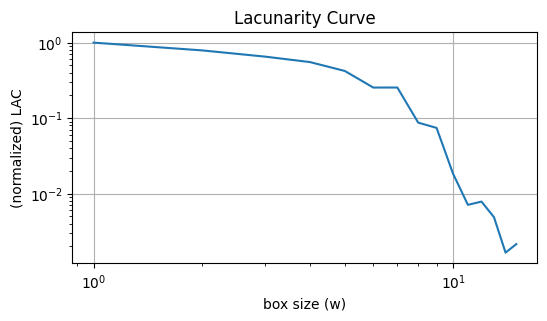

In [24]:
# normalized LAC

lac = grqa.lacunarity(mass_distribution, mass_distribution_reverse, mass_distribution_z2, mass_distribution_reverse_z2, nr_boxes)

fig, ax = plt.subplots(1, 1, figsize=(6, 3))

ax.loglog(np.arange(max_box_size+1), lac)
ax.set_xlabel("box size (w)")
ax.set_ylabel("(normalized) LAC")
ax.set_title("Lacunarity Curve")
ax.grid()

plt.show()
plt.close()

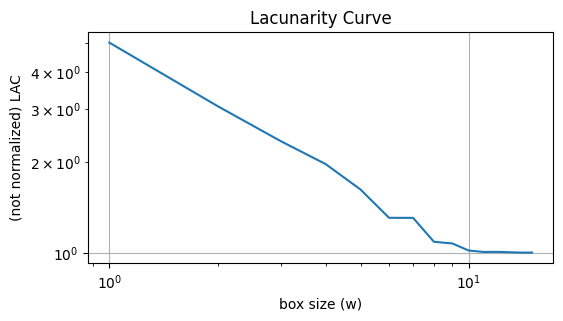

In [25]:
# not normalized LAC

lac = grqa.lacunarity_not_normalized(mass_distribution, mass_distribution_z2, nr_boxes)

fig, ax = plt.subplots(1, 1, figsize=(6, 3))

ax.loglog(np.arange(max_box_size+1), lac)
ax.set_xlabel("box size (w)")
ax.set_ylabel("(not normalized) LAC")
ax.set_title("Lacunarity Curve")
ax.grid()

plt.show()
plt.close()

This notebook showed how to compute and plot the distance matrix and the recurrence plot of an image, and how to detect patterns in the image that form certain structures (diagonal/vertical/horizontal lines/patches) in the recurrence plot. Then, the number and length/size of the structures were computed, as well as the sum of the masses for different box sizes. From these intermediate results, the measures of the Recurrence Quantification Analysis (RQA), including the lacunarity, were calculated.

To understand and reproduce the results from the thesis, consider the ``README.md`` and ``run_grqa.py``.